In [1]:
import pandas as pd
import pickle
import os
import time
import cv2
import math
import random
import shutil
import pathlib
import seaborn as sns
import numpy as np
from numpy import where
import matplotlib.pyplot as plt
from PIL import Image
from matplotlib import pyplot
import os
import time
from imblearn.over_sampling import ADASYN
from collections import (Counter, defaultdict)
import tensorflow as tf
from scipy import stats
from tensorflow.keras import layers
from tensorflow.python import train
from keras.models import Sequential
from keras.layers import Dense
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import RFE
import keras.callbacks as kcallbacks
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import (QuantileTransformer, LabelEncoder)
from sklearn.metrics import (det_curve, balanced_accuracy_score, cohen_kappa_score, hinge_loss, matthews_corrcoef, 
                             top_k_accuracy_score, hamming_loss, jaccard_score, log_loss, zero_one_loss, classification_report,
                             accuracy_score, precision_score, roc_auc_score, average_precision_score, recall_score, f1_score, 
                             mean_squared_error, mean_absolute_error, confusion_matrix, r2_score)

2023-08-31 00:53:22.998165: I tensorflow/core/util/port.cc:110] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2023-08-31 00:53:24.021353: I tensorflow/tsl/cuda/cudart_stub.cc:28] Could not find cuda drivers on your machine, GPU will not be used.
2023-08-31 00:53:25.114211: I tensorflow/tsl/cuda/cudart_stub.cc:28] Could not find cuda drivers on your machine, GPU will not be used.
2023-08-31 00:53:25.164906: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2023-08-31 00:55:19.719371: W tensorflow/compiler/tf2tensorrt/utils/py_utils.cc:38] TF-TRT Warning: Co

In [3]:
df=pd.read_csv('ORG_GPS Spoofing.csv')

In [4]:
df

,timestamp,q[0],q[1],q[2],q[3],delta_q_reset[0],delta_q_reset[1],delta_q_reset[2],delta_q_reset[3],quat_reset_counter,...,v_xy_valid,v_z_valid,xy_reset_counter,z_reset_counter,vxy_reset_counter,vz_reset_counter,xy_global,z_global,dist_bottom_valid,label
0,0,0.645777,0.000595,-0.014430,0.763389,0.645768,-4.656613e-10,9.313227e-10,0.763534,1.0,...,1.0,1.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0,benign
1,4000,0.645777,0.000595,-0.014430,0.763389,0.645768,-4.656613e-10,9.313227e-10,0.763534,1.0,...,1.0,1.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0,benign
2,8000,0.645777,0.000595,-0.014430,0.763389,0.645768,-4.656613e-10,9.313227e-10,0.763534,1.0,...,1.0,1.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0,benign
3,12000,0.645777,0.000595,-0.014430,0.763389,0.645768,-4.656613e-10,9.313227e-10,0.763534,1.0,...,1.0,1.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0,benign
4,16000,0.645777,0.000595,-0.014430,0.763389,0.645768,-4.656613e-10,9.313227e-10,0.763534,1.0,...,1.0,1.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0,benign
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
475087,521852000,-0.992084,-0.006269,-0.004327,0.125347,0.999946,0.000000e+00,4.656613e-10,0.010412,3.0,...,1.0,1.0,4.0,0.0,4.0,4.0,1.0,1.0,0.0,benign
475088,521900000,-0.992101,-0.006275,-0.004315,0.125208,0.999946,0.000000e+00,4.656613e-10,0.010412,3.0,...,1.0,1.0,4.0,0.0,4.0,4.0,1.0,1.0,0.0,benign
475089,521924000,-0.992111,-0.006311,-0.004307,0.125130,0.999946,0.000000e+00,4.656613e-10,0.010412,3.0,...,1.0,1.0,4.0,0.0,4.0,4.0,1.0,1.0,0.0,benign
475090,521948000,-0.992121,-0.006346,-0.004299,0.125052,0.999946,0.000000e+00,4.656613e-10,0.010412,3.0,...,1.0,1.0,4.0,0.0,4.0,4.0,1.0,1.0,0.0,benign


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 475092 entries, 0 to 475091
Data columns (total 85 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   timestamp              475092 non-null  int64  
 1   q[0]                   475092 non-null  float64
 2   q[1]                   475092 non-null  float64
 3   q[2]                   475092 non-null  float64
 4   q[3]                   475092 non-null  float64
 5   delta_q_reset[0]       475092 non-null  float64
 6   delta_q_reset[1]       475092 non-null  float64
 7   delta_q_reset[2]       475092 non-null  float64
 8   delta_q_reset[3]       475092 non-null  float64
 9   quat_reset_counter     475092 non-null  float64
 10  lat_x                  475092 non-null  float64
 11  lon_x                  475092 non-null  float64
 12  alt_x                  475092 non-null  float64
 13  alt_ellipsoid_x        475092 non-null  float64
 14  delta_alt              475092 non-nu

In [6]:
target_column = 'label'
X = df.drop(columns=[target_column])
y = df[target_column]
clf = RandomForestClassifier()
rfe = RFE(estimator=clf, n_features_to_select=1)
rfe.fit(X, y)

feature_ranking = rfe.ranking_
print("Feature Ranking:")
for rank, feature in zip(feature_ranking, X.columns):
    print(f"Rank {rank}: {feature}")

feature_mask = rfe.support_
timeframe_selected = feature_mask[X.columns.tolist().index("timestamp")]
if timeframe_selected:
    print("The timeframe feature is selected as an important feature.")
else:
    print("The timeframe feature is not selected as an important feature.")

Feature Ranking:
Rank 14: timestamp
Rank 40: q[0]
Rank 13: q[1]
Rank 32: q[2]
Rank 35: q[3]
Rank 46: delta_q_reset[0]
Rank 55: delta_q_reset[1]
Rank 53: delta_q_reset[2]
Rank 38: delta_q_reset[3]
Rank 59: quat_reset_counter
Rank 3: lat_x
Rank 1: lon_x
Rank 37: alt_x
Rank 24: alt_ellipsoid_x
Rank 70: delta_alt
Rank 22: vel_n
Rank 18: vel_e
Rank 52: vel_d
Rank 31: yaw_x
Rank 19: eph_x
Rank 50: epv_x
Rank 76: terrain_alt
Rank 12: lat_lon_reset_counter
Rank 77: alt_reset_counter
Rank 64: terrain_alt_valid
Rank 80: dead_reckoning
Rank 21: time_utc_usec
Rank 16: lat_y
Rank 15: lon_y
Rank 42: alt_y
Rank 73: alt_ellipsoid_y
Rank 49: s_variance_m_s
Rank 54: c_variance_rad
Rank 62: eph_y
Rank 67: epv_y
Rank 75: hdop
Rank 78: vdop
Rank 58: noise_per_ms
Rank 72: jamming_indicator
Rank 44: vel_m_s
Rank 39: vel_n_m_s
Rank 26: vel_e_m_s
Rank 51: vel_d_m_s
Rank 28: cog_rad
Rank 81: fix_type
Rank 66: vel_ned_valid
Rank 60: satellites_used
Rank 65: ref_lat
Rank 71: ref_lon
Rank 2: x
Rank 4: y
Rank 30: z

In [7]:
df['label'].value_counts()

benign       463526
malicious     11566
Name: label, dtype: int64

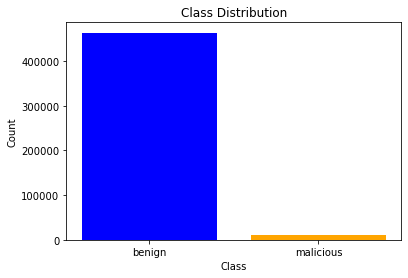

In [8]:
class_count = df['label'].value_counts()
colors = ['blue', 'orange']
plt.bar(class_count.index, class_count.values, color=colors)
plt.title('Class Distribution')
plt.xlabel('Class')
plt.ylabel('Count')
plt.savefig('Class Distribution_GPS_SPOOFING.pdf', format='pdf', dpi=300)
plt.savefig('Class Distribution_GPS_SPOOFING.png', format='png', dpi=300)
plt.savefig('Class Distribution_GPS_SPOOFING.svg', format='svg')
plt.show()

In [9]:
df['label'].value_counts()

benign       463526
malicious     11566
Name: label, dtype: int64

In [10]:
df = df.drop(columns=['timestamp'])

In [11]:
df

,q[0],q[1],q[2],q[3],delta_q_reset[0],delta_q_reset[1],delta_q_reset[2],delta_q_reset[3],quat_reset_counter,lat_x,...,v_xy_valid,v_z_valid,xy_reset_counter,z_reset_counter,vxy_reset_counter,vz_reset_counter,xy_global,z_global,dist_bottom_valid,label
0,0.645777,0.000595,-0.014430,0.763389,0.645768,-4.656613e-10,9.313227e-10,0.763534,1.0,43.945155,...,1.0,1.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0,benign
1,0.645777,0.000595,-0.014430,0.763389,0.645768,-4.656613e-10,9.313227e-10,0.763534,1.0,43.945155,...,1.0,1.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0,benign
2,0.645777,0.000595,-0.014430,0.763389,0.645768,-4.656613e-10,9.313227e-10,0.763534,1.0,43.945155,...,1.0,1.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0,benign
3,0.645777,0.000595,-0.014430,0.763389,0.645768,-4.656613e-10,9.313227e-10,0.763534,1.0,43.945155,...,1.0,1.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0,benign
4,0.645777,0.000595,-0.014430,0.763389,0.645768,-4.656613e-10,9.313227e-10,0.763534,1.0,43.945155,...,1.0,1.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0,benign
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
475087,-0.992084,-0.006269,-0.004327,0.125347,0.999946,0.000000e+00,4.656613e-10,0.010412,3.0,43.945155,...,1.0,1.0,4.0,0.0,4.0,4.0,1.0,1.0,0.0,benign
475088,-0.992101,-0.006275,-0.004315,0.125208,0.999946,0.000000e+00,4.656613e-10,0.010412,3.0,43.945155,...,1.0,1.0,4.0,0.0,4.0,4.0,1.0,1.0,0.0,benign
475089,-0.992111,-0.006311,-0.004307,0.125130,0.999946,0.000000e+00,4.656613e-10,0.010412,3.0,43.945155,...,1.0,1.0,4.0,0.0,4.0,4.0,1.0,1.0,0.0,benign
475090,-0.992121,-0.006346,-0.004299,0.125052,0.999946,0.000000e+00,4.656613e-10,0.010412,3.0,43.945155,...,1.0,1.0,4.0,0.0,4.0,4.0,1.0,1.0,0.0,benign


In [12]:
num_features = df.shape[1]
print("The number of features in the dataset is: ", num_features)

The number of features in the dataset is:  84


In [13]:
duplicates = df.duplicated()
print("Number of duplicate rows: ", duplicates.sum())

Number of duplicate rows:  227


In [14]:
df.drop_duplicates(inplace=True)

In [15]:
df['label'].value_counts()

benign       463299
malicious     11566
Name: label, dtype: int64

In [16]:
print("Number of rows before removing duplicates: ", df.shape[0])
df.drop_duplicates(inplace=True)
print("Number of rows after removing duplicates: ", df.shape[0])

Number of rows before removing duplicates:  474865
Number of rows after removing duplicates:  474865


In [17]:
duplicates = df.duplicated()
print("Number of duplicate rows: ", duplicates.sum())

Number of duplicate rows:  0


In [18]:
print(df.isnull().sum())

q[0]                 0
q[1]                 0
q[2]                 0
q[3]                 0
delta_q_reset[0]     0
                    ..
vz_reset_counter     0
xy_global            0
z_global             0
dist_bottom_valid    0
label                0
Length: 84, dtype: int64


In [19]:
if df.isna().sum().sum() > 0:
    print("There are NaN values in the dataset.")
else:
    print("There are no NaN values in the dataset.")

There are no NaN values in the dataset.


In [20]:
numeric_features = df.dtypes[df.dtypes != 'object'].index
scaler = QuantileTransformer()  
df[numeric_features] = scaler.fit_transform(df[numeric_features])

In [21]:
df[numeric_features]

,q[0],q[1],q[2],q[3],delta_q_reset[0],delta_q_reset[1],delta_q_reset[2],delta_q_reset[3],quat_reset_counter,lat_x,...,z_valid,v_xy_valid,v_z_valid,xy_reset_counter,z_reset_counter,vxy_reset_counter,vz_reset_counter,xy_global,z_global,dist_bottom_valid
0,0.896214,0.870201,0.417153,0.978146,0.00000,0.842296,0.910310,1.00000,0.000000,0.432361,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
58,0.896214,0.870201,0.417153,0.978146,0.00000,0.842296,0.910310,1.00000,0.000000,0.432361,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
59,0.896214,0.870201,0.417153,0.978146,0.00000,0.842296,0.910310,1.00000,0.000000,0.432361,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
60,0.896214,0.870201,0.417153,0.978146,0.00000,0.842296,0.910310,1.00000,0.000000,0.432361,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
61,0.896214,0.870201,0.417153,0.978146,0.00000,0.842296,0.910310,1.00000,0.000000,0.432361,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
475087,0.016722,0.825917,0.465335,0.908176,0.02002,0.863864,0.890891,0.97998,0.153654,0.436090,...,0.0,1.0,0.0,1.0,0.0,1.0,1.0,1.0,1.0,0.0
475088,0.016691,0.825891,0.465432,0.908146,0.02002,0.863864,0.890891,0.97998,0.153654,0.436090,...,0.0,1.0,0.0,1.0,0.0,1.0,1.0,1.0,1.0,0.0
475089,0.016674,0.825751,0.465491,0.908130,0.02002,0.863864,0.890891,0.97998,0.153654,0.436090,...,0.0,1.0,0.0,1.0,0.0,1.0,1.0,1.0,1.0,0.0
475090,0.016658,0.825618,0.465549,0.908114,0.02002,0.863864,0.890891,0.97998,0.153654,0.436090,...,0.0,1.0,0.0,1.0,0.0,1.0,1.0,1.0,1.0,0.0


In [22]:
labelencoder = LabelEncoder()
df.iloc[:, -1] = labelencoder.fit_transform(df.iloc[:, -1])

In [23]:
df

,q[0],q[1],q[2],q[3],delta_q_reset[0],delta_q_reset[1],delta_q_reset[2],delta_q_reset[3],quat_reset_counter,lat_x,...,v_xy_valid,v_z_valid,xy_reset_counter,z_reset_counter,vxy_reset_counter,vz_reset_counter,xy_global,z_global,dist_bottom_valid,label
0,0.896214,0.870201,0.417153,0.978146,0.00000,0.842296,0.910310,1.00000,0.000000,0.432361,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0
58,0.896214,0.870201,0.417153,0.978146,0.00000,0.842296,0.910310,1.00000,0.000000,0.432361,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0
59,0.896214,0.870201,0.417153,0.978146,0.00000,0.842296,0.910310,1.00000,0.000000,0.432361,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0
60,0.896214,0.870201,0.417153,0.978146,0.00000,0.842296,0.910310,1.00000,0.000000,0.432361,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0
61,0.896214,0.870201,0.417153,0.978146,0.00000,0.842296,0.910310,1.00000,0.000000,0.432361,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
475087,0.016722,0.825917,0.465335,0.908176,0.02002,0.863864,0.890891,0.97998,0.153654,0.436090,...,1.0,0.0,1.0,0.0,1.0,1.0,1.0,1.0,0.0,0
475088,0.016691,0.825891,0.465432,0.908146,0.02002,0.863864,0.890891,0.97998,0.153654,0.436090,...,1.0,0.0,1.0,0.0,1.0,1.0,1.0,1.0,0.0,0
475089,0.016674,0.825751,0.465491,0.908130,0.02002,0.863864,0.890891,0.97998,0.153654,0.436090,...,1.0,0.0,1.0,0.0,1.0,1.0,1.0,1.0,0.0,0
475090,0.016658,0.825618,0.465549,0.908114,0.02002,0.863864,0.890891,0.97998,0.153654,0.436090,...,1.0,0.0,1.0,0.0,1.0,1.0,1.0,1.0,0.0,0


In [24]:
df['label'].value_counts()

0    463299
1     11566
Name: label, dtype: int64

In [25]:
df.shape

(474865, 84)

In [26]:
df.to_csv("QuantileTransformer_GPS_Spoofing.csv", index=False)

In [27]:
df=pd.read_csv('QuantileTransformer_GPS_Spoofing.csv')

In [28]:
df

,q[0],q[1],q[2],q[3],delta_q_reset[0],delta_q_reset[1],delta_q_reset[2],delta_q_reset[3],quat_reset_counter,lat_x,...,v_xy_valid,v_z_valid,xy_reset_counter,z_reset_counter,vxy_reset_counter,vz_reset_counter,xy_global,z_global,dist_bottom_valid,label
0,0.896214,0.870201,0.417153,0.978146,0.00000,0.842296,0.910310,1.00000,0.000000,0.432361,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0
1,0.896214,0.870201,0.417153,0.978146,0.00000,0.842296,0.910310,1.00000,0.000000,0.432361,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0
2,0.896214,0.870201,0.417153,0.978146,0.00000,0.842296,0.910310,1.00000,0.000000,0.432361,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0
3,0.896214,0.870201,0.417153,0.978146,0.00000,0.842296,0.910310,1.00000,0.000000,0.432361,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0
4,0.896214,0.870201,0.417153,0.978146,0.00000,0.842296,0.910310,1.00000,0.000000,0.432361,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
474860,0.016722,0.825917,0.465335,0.908176,0.02002,0.863864,0.890891,0.97998,0.153654,0.436090,...,1.0,0.0,1.0,0.0,1.0,1.0,1.0,1.0,0.0,0
474861,0.016691,0.825891,0.465432,0.908146,0.02002,0.863864,0.890891,0.97998,0.153654,0.436090,...,1.0,0.0,1.0,0.0,1.0,1.0,1.0,1.0,0.0,0
474862,0.016674,0.825751,0.465491,0.908130,0.02002,0.863864,0.890891,0.97998,0.153654,0.436090,...,1.0,0.0,1.0,0.0,1.0,1.0,1.0,1.0,0.0,0
474863,0.016658,0.825618,0.465549,0.908114,0.02002,0.863864,0.890891,0.97998,0.153654,0.436090,...,1.0,0.0,1.0,0.0,1.0,1.0,1.0,1.0,0.0,0


In [29]:
df['label'].value_counts()

0    463299
1     11566
Name: label, dtype: int64

In [30]:
df.shape

(474865, 84)

# PCA

In [31]:
X = df.drop(['label'],axis=1).values
y = df.iloc[:, -1].values.reshape(-1,1)
y=np.ravel(y)
X_train, X_test, y_train, y_test = train_test_split(X,y, train_size = 0.8, test_size = 0.2, random_state = 0,stratify = y)

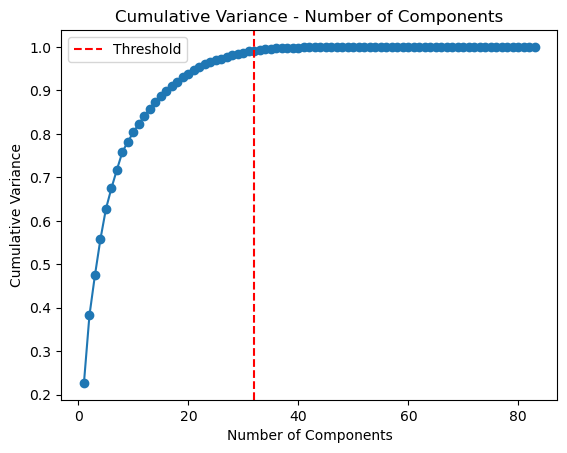

The number of components that exceed the threshold (0.99) is: 32


In [32]:
threshold = 0.99 
pca = PCA()
pca.fit(X)

cumulative_variance = np.cumsum(pca.explained_variance_ratio_)
num_components_threshold = np.argmax(cumulative_variance >= threshold) + 1

plt.plot(range(1, len(cumulative_variance) + 1), cumulative_variance, marker='o')
plt.xlabel('Number of Components')
plt.ylabel('Cumulative Variance')
plt.title('Cumulative Variance - Number of Components')
plt.axvline(x=num_components_threshold, color='r', linestyle='--', label='Threshold')
plt.legend()
plt.show()

print(f"The number of components that exceed the threshold ({threshold}) is: {num_components_threshold}")

In [33]:
X = df.drop(['label'], axis=1)
y = df['label']

pca = PCA(n_components=32)
X_pca = pca.fit_transform(X)

pca_df = pd.DataFrame(X_pca, columns=[f'PC{i}' for i in range(1, 33)])
pca_df['label'] = y
pca_df.to_csv('pca_dataset.csv', index=False)

In [34]:
df = pd.read_csv('pca_dataset.csv')

In [35]:
df

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,...,PC24,PC25,PC26,PC27,PC28,PC29,PC30,PC31,PC32,label
0,1.180295,-0.332333,1.055928,0.529204,-0.249127,0.208468,-1.556456,0.691734,-0.505653,-0.167445,...,0.267187,0.197453,-0.013823,-0.801281,0.269407,-0.224594,0.552767,-0.136141,0.044864,0
1,1.167935,-0.479326,1.097296,0.559072,-0.159723,0.341847,-1.425987,0.696011,-0.356284,-0.181029,...,0.231642,0.250507,0.069940,-0.789451,0.261557,-0.227750,0.427130,0.040583,0.037368,0
2,1.178273,-0.466248,1.086082,0.507315,0.039700,0.174693,-1.449793,0.791179,-0.442792,-0.228615,...,0.235372,0.178447,0.057762,-0.773013,0.305819,-0.185869,0.409944,0.153134,0.019805,0
3,1.166357,-0.463715,1.057523,0.520311,-0.157858,0.330349,-1.443913,0.804812,-0.383437,-0.227171,...,0.265627,0.202215,0.034358,-0.761889,0.277944,-0.214240,0.443939,0.041701,0.032717,0
4,1.167070,-0.460548,1.052940,0.512727,-0.142641,0.317697,-1.447525,0.821996,-0.392869,-0.234855,...,0.272358,0.194305,0.027539,-0.759100,0.278877,-0.212542,0.450752,0.029125,0.034730,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
474860,1.533475,1.422650,0.987436,0.332146,0.148048,-0.189172,0.262504,0.664529,-0.038303,0.166492,...,0.056963,0.450412,-0.433882,-0.362128,0.430026,-0.203227,-0.428038,0.284543,-0.370444,0
474861,1.526935,1.418557,0.976826,0.322434,0.149381,-0.190204,0.305649,0.675459,-0.057833,0.203845,...,0.043697,0.492045,-0.454699,-0.358618,0.422645,-0.199225,-0.427158,0.279025,-0.352308,0
474862,1.519063,1.418017,0.966168,0.316142,0.150565,-0.190243,0.346592,0.682150,-0.073472,0.230727,...,0.036299,0.520092,-0.468832,-0.358950,0.419060,-0.194673,-0.428141,0.275538,-0.331362,0
474863,1.519049,1.418009,0.966151,0.316158,0.150553,-0.190231,0.346602,0.682135,-0.073466,0.230710,...,0.036250,0.520082,-0.468848,-0.358964,0.419129,-0.194642,-0.428110,0.275533,-0.331359,0


# ADASYN

In [3]:
df = pd.read_csv('pca_dataset.csv')

In [4]:
df

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,...,PC24,PC25,PC26,PC27,PC28,PC29,PC30,PC31,PC32,label
0,1.180295,-0.332333,1.055928,0.529204,-0.249127,0.208468,-1.556456,0.691734,-0.505653,-0.167445,...,0.267187,0.197453,-0.013823,-0.801281,0.269407,-0.224594,0.552767,-0.136141,0.044864,0
1,1.167935,-0.479326,1.097296,0.559072,-0.159723,0.341847,-1.425987,0.696011,-0.356284,-0.181029,...,0.231642,0.250507,0.069940,-0.789451,0.261557,-0.227750,0.427130,0.040583,0.037368,0
2,1.178273,-0.466248,1.086082,0.507315,0.039700,0.174693,-1.449793,0.791179,-0.442792,-0.228615,...,0.235372,0.178447,0.057762,-0.773013,0.305819,-0.185869,0.409944,0.153134,0.019805,0
3,1.166357,-0.463715,1.057523,0.520311,-0.157858,0.330349,-1.443913,0.804812,-0.383437,-0.227171,...,0.265627,0.202215,0.034358,-0.761889,0.277944,-0.214240,0.443939,0.041701,0.032717,0
4,1.167070,-0.460548,1.052940,0.512727,-0.142641,0.317697,-1.447525,0.821996,-0.392869,-0.234855,...,0.272358,0.194305,0.027539,-0.759100,0.278877,-0.212542,0.450752,0.029125,0.034730,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
474860,1.533475,1.422650,0.987436,0.332146,0.148048,-0.189172,0.262504,0.664529,-0.038303,0.166492,...,0.056963,0.450412,-0.433882,-0.362128,0.430026,-0.203227,-0.428038,0.284543,-0.370444,0
474861,1.526935,1.418557,0.976826,0.322434,0.149381,-0.190204,0.305649,0.675459,-0.057833,0.203845,...,0.043697,0.492045,-0.454699,-0.358618,0.422645,-0.199225,-0.427158,0.279025,-0.352308,0
474862,1.519063,1.418017,0.966168,0.316142,0.150565,-0.190243,0.346592,0.682150,-0.073472,0.230727,...,0.036299,0.520092,-0.468832,-0.358950,0.419060,-0.194673,-0.428141,0.275538,-0.331362,0
474863,1.519049,1.418009,0.966151,0.316158,0.150553,-0.190231,0.346602,0.682135,-0.073466,0.230710,...,0.036250,0.520082,-0.468848,-0.358964,0.419129,-0.194642,-0.428110,0.275533,-0.331359,0


In [5]:
df['label'].value_counts()

0    463299
1     11566
Name: label, dtype: int64

In [6]:
X = df.drop(['label'],axis=1).values
y = df.iloc[:, -1].values.reshape(-1,1)
y=np.ravel(y)

Counter({0: 370589, 1: 9303})
Counter({0: 370589, 1: 360004})


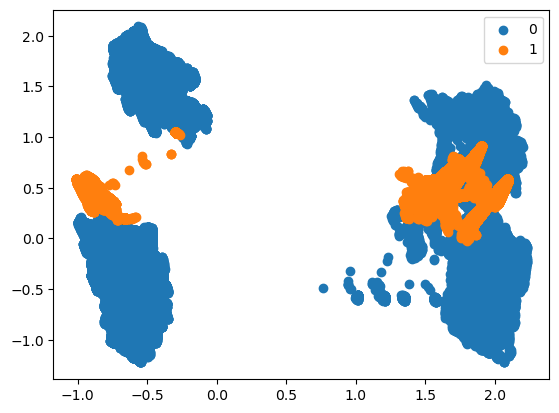

In [8]:
X_train, X_test, y_train, y_test = train_test_split(X,y, train_size = 0.8, test_size = 0.2, random_state = 0)
oversample = ADASYN(sampling_strategy={1: 360000})
X_train_oversampled, y_train_oversampled = oversample.fit_resample(X_train, y_train)
print(Counter(y_train))
print(Counter(y_train_oversampled))
for label, _ in Counter(y_train_oversampled).items():
    row_ix = where(y_train_oversampled == label)[0]
    pyplot.scatter(X_train_oversampled[row_ix, 0], X_train_oversampled[row_ix, 1], label=str(label))
pyplot.legend()
pyplot.show()

In [9]:
df = pd.DataFrame(X_train_oversampled)
df['label'] = y_train_oversampled
df.to_csv('GPS Spoofing_ADASYN.csv', index=False)

In [10]:
df = pd.read_csv('GPS Spoofing_ADASYN.csv')

In [11]:
df['label'].value_counts()

0    370589
1    360004
Name: label, dtype: int64

In [12]:
X = df.drop(['label'],axis=1).values
y = df.iloc[:, -1].values.reshape(-1,1)
y=np.ravel(y)
X_train, X_test, y_train, y_test = train_test_split(X,y, train_size = 0.8, test_size = 0.2, random_state = 0,stratify = y)

In [13]:
pd.Series(y_train).value_counts()

0    296471
1    288003
dtype: int64

In [15]:
df = pd.read_csv('GPS Spoofing_ADASYN.csv')

In [16]:
df['label'].value_counts()

0    370589
1    360004
Name: label, dtype: int64

In [17]:
df

,0,1,2,3,4,5,6,7,8,9,...,23,24,25,26,27,28,29,30,31,label
0,-0.716021,1.772014,-0.270128,-0.215260,-0.167244,-0.231929,0.175768,1.336688,-0.130626,-0.249322,...,0.111480,0.132168,-0.152680,-0.034823,-0.060700,-0.118601,-0.027488,-0.124926,-0.015057,0
1,-0.615780,-0.880004,-0.834186,-0.539950,-0.451302,0.774486,0.097541,0.580133,0.287805,0.407272,...,-0.116806,0.014311,0.006513,0.102355,-0.018903,0.072387,0.009497,-0.011791,-0.016777,0
2,1.452770,-0.146694,1.002675,0.560042,-0.137343,-0.121293,-0.297929,0.863863,-0.453517,0.342142,...,0.712797,0.083588,0.449351,0.114603,0.602620,0.087095,0.806727,0.221150,0.123638,0
3,-0.653890,-0.660766,-0.758382,0.581292,-0.217508,-0.395115,-0.202910,-0.005741,0.021250,0.069546,...,0.213399,-0.128094,-0.118907,0.044825,-0.004897,0.009983,0.035712,0.042237,-0.001520,0
4,-0.681280,-0.848875,-0.798631,0.393023,-0.431811,-0.837040,0.338630,-0.016788,0.045479,0.260310,...,-0.128597,0.190708,0.069914,-0.091941,-0.064094,0.012162,0.020594,-0.076379,0.029255,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
730588,1.705110,0.612467,1.821935,-0.149597,1.000067,0.658040,-0.555026,-0.524113,0.422437,-0.036732,...,-0.157769,0.010670,-0.143474,-0.256033,0.102642,0.202373,0.199899,0.022517,-0.095281,1
730589,1.874474,0.647168,1.816566,-0.162039,0.881301,0.541953,-0.491011,-0.527984,0.446712,-0.204857,...,-0.126316,-0.151104,-0.142661,-0.191330,0.041701,0.165176,0.011171,0.078383,-0.047457,1
730590,1.543826,0.579652,1.826518,-0.137495,1.113193,0.769211,-0.614438,-0.520121,0.399521,0.123293,...,-0.187048,0.163935,-0.144230,-0.317661,0.160334,0.237183,0.379199,-0.030638,-0.144328,1
730591,1.601976,0.590757,1.827628,-0.144803,1.073359,0.727464,-0.596170,-0.526462,0.409630,0.041019,...,-0.167583,0.122419,-0.126345,-0.266125,0.167874,0.251342,0.336143,-0.050992,-0.154239,1


In [18]:
df['label'] = df['label'].replace({0: 'Benign', 1: 'GPS Spoofing'})
print(df['label'].value_counts())

Benign          370589
GPS Spoofing    360004
Name: label, dtype: int64


In [19]:
numeric_features = df.dtypes[df.dtypes != 'object'].index

In [20]:
df[numeric_features] = df[numeric_features].apply(
    lambda x: (x*255))

In [22]:
df.shape 

(730593, 33)

In [23]:
df.label.value_counts()

Benign          370589
GPS Spoofing    360004
Name: label, dtype: int64

In [24]:
df.to_csv('GPS Spoofing[Processed].csv', index=False)

In [9]:
df = pd.read_csv('GPS Spoofing[Processed].csv')

In [10]:
df

,0,1,2,3,4,5,6,7,8,9,...,23,24,25,26,27,28,29,30,31,label
0,-183.012841,452.063366,-68.433412,-54.999419,-42.795768,-59.449250,46.232048,340.751023,-33.616790,-63.439907,...,27.163415,33.916727,-39.445326,-8.433644,-15.614193,-30.235853,-7.081803,-32.038771,-3.739907,Benign
1,-156.759092,-224.640630,-211.676607,-138.680306,-114.754361,197.403619,26.248224,148.415658,73.991982,103.575857,...,-30.190338,3.267212,2.716002,26.035673,-4.227583,18.487631,2.370425,-2.884178,-4.198326,Benign
2,370.306490,-37.550210,254.788438,144.062873,-35.079014,-31.016569,-75.039129,220.893910,-115.109587,87.999131,...,183.253222,22.210270,112.516209,27.832088,151.766703,21.709945,206.047288,56.085672,31.614425,Benign
3,-166.468999,-168.484563,-194.047088,146.774493,-56.138923,-100.775789,-51.937872,-1.328963,5.467926,18.009496,...,53.827496,-31.693426,-31.690225,11.650549,-0.735206,2.707078,9.223920,10.736723,-0.179331,Benign
4,-173.597425,-216.383309,-204.179191,99.036883,-110.478079,-213.439686,86.032134,-4.835344,11.675245,66.488310,...,-32.458640,48.202323,18.447698,-23.312006,-16.802004,3.016828,5.421885,-19.938210,7.265375,Benign
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
730588,430.638458,154.832216,465.177729,-35.859146,258.030146,170.606164,-143.167480,-133.593647,107.422057,-9.531236,...,-40.036266,9.021140,-32.903294,-61.933162,33.230712,56.279724,59.329448,-2.518228,-29.865454,GPS Spoofing
730589,473.422314,163.663844,463.517450,-38.618865,227.712589,141.148877,-127.055343,-134.051389,113.048184,-47.485976,...,-33.400965,-34.183566,-36.159389,-50.332039,12.678948,42.963353,7.717959,18.705077,-12.290804,GPS Spoofing
730590,427.505902,167.727097,463.905792,-31.865301,278.338118,195.215706,-145.135487,-132.364937,114.700225,4.109195,...,-45.169689,33.157479,-33.031698,-79.270053,41.753334,56.259801,94.371128,-24.662015,-45.178094,GPS Spoofing
730591,457.171852,162.481417,463.749675,-37.219318,245.577043,159.470512,-135.403911,-133.530660,112.178835,-29.222399,...,-34.462330,-9.267589,-31.980098,-54.774710,28.274545,53.528040,32.170450,2.464630,-24.499888,GPS Spoofing


In [11]:
df.label.value_counts()

Benign          370589
GPS Spoofing    360004
Name: label, dtype: int64

In [12]:
random.seed(123)
np.random.seed(123)
tf.random.set_seed(123)

In [13]:
df.shape

(730593, 33)

In [14]:
df0=df[df['label']=='Benign'].drop(['label'],axis=1)
df1=df[df['label']=='GPS Spoofing'].drop(['label'],axis=1)

In [15]:
count=0
ims = []
image_path = "train/0/"
os.makedirs(image_path)

for i in range(0, len(df0)):  
    count=count+1
    if count<=32*3: 
        im=df0.iloc[i].values
        ims=np.append(ims,im)
    else:
        ims=np.array(ims).reshape(32,32,3)
        array = np.array(ims, dtype=np.uint8)
        new_image = Image.fromarray(array)
        new_image.save(image_path+str(i)+'.png')
        count=0
        ims = []

In [16]:
count=0
ims = []
image_path = "train/1/"
os.makedirs(image_path)

for i in range(0, len(df1)):  
    count=count+1
    if count<=32*3: 
        im=df1.iloc[i].values
        ims=np.append(ims,im)
    else:
        ims=np.array(ims).reshape(32,32,3)
        array = np.array(ims, dtype=np.uint8)
        new_image = Image.fromarray(array)
        new_image.save(image_path+str(i)+'.png')
        count=0
        ims = []

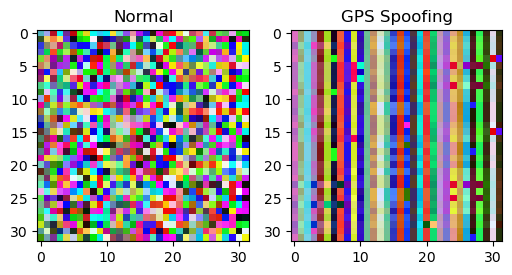

In [17]:
img1 = Image.open('train/0/100006.png')
img2 = Image.open('train/1/100006.png')
plt.figure(figsize=(6, 9)) 
plt.subplot(1,2,1)
plt.imshow(img1)
plt.title("Normal")
plt.subplot(1,2,2)
plt.imshow(img2)
plt.title("GPS Spoofing")

plt.savefig('Normal+GPS Spoofing.pdf', format='pdf', dpi=300)
plt.savefig('Normal+GPS Spoofing.svg', format='svg')
plt.savefig('Normal+GPS Spoofing.png', format='png', dpi=300)
plt.show()

In [18]:
data_dir = pathlib.Path('train')
data_dir

PosixPath('train')

In [19]:
batch_size = 32
img_height = 224
img_width = 224

train_ds = tf.keras.utils.image_dataset_from_directory(
  data_dir,
  validation_split=0.2,
  subset="training",
  seed=123,
  image_size=(img_height, img_width),
  batch_size=batch_size)

val_ds = tf.keras.utils.image_dataset_from_directory(
  data_dir,
  validation_split=0.2,
  subset="validation",
  seed=123,
  image_size=(img_height, img_width),
  batch_size=batch_size)

val_batches = tf.data.experimental.cardinality(val_ds) 
test_ds = val_ds.take(val_batches // 3)
val_ds = val_ds.skip(val_batches // 3)
class_names = train_ds.class_names
num_classes = len(class_names)

print(class_names)

print('Number of validation batches: %d' % tf.data.experimental.cardinality(val_ds))
print('Number of test batches: %d' % tf.data.experimental.cardinality(test_ds))

Found 7531 files belonging to 2 classes.
Using 6025 files for training.


2023-08-31 00:59:04.508042: E tensorflow/compiler/xla/stream_executor/cuda/cuda_driver.cc:266] failed call to cuInit: CUDA_ERROR_NO_DEVICE: no CUDA-capable device is detected


Found 7531 files belonging to 2 classes.
Using 1506 files for validation.
['0', '1']
Number of validation batches: 32
Number of test batches: 16


In [20]:
data_augmentation = tf.keras.Sequential([
  layers.RandomFlip("horizontal_and_vertical"),
  layers.RandomRotation(0.2),
  layers.RandomZoom(0.1),
])

2023-08-31 00:59:06.838430: I tensorflow/core/common_runtime/executor.cc:1197] [/device:CPU:0] (DEBUG INFO) Executor start aborting (this does not indicate an error and you can ignore this message): INVALID_ARGUMENT: You must feed a value for placeholder tensor 'Placeholder/_4' with dtype int32 and shape [6025]
	 [[{{node Placeholder/_4}}]]
2023-08-31 00:59:06.838786: I tensorflow/core/common_runtime/executor.cc:1197] [/device:CPU:0] (DEBUG INFO) Executor start aborting (this does not indicate an error and you can ignore this message): INVALID_ARGUMENT: You must feed a value for placeholder tensor 'Placeholder/_0' with dtype string and shape [6025]
	 [[{{node Placeholder/_0}}]]


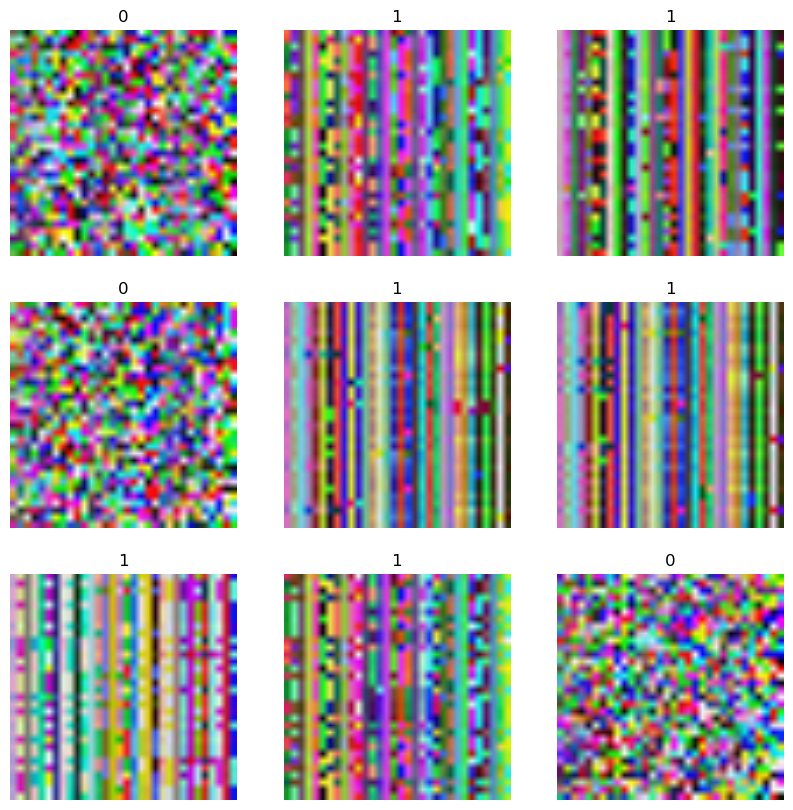

In [21]:
class_names = train_ds.class_names
plt.figure(figsize=(10, 10))
for images, label in train_ds.take(1):
  for i in range(9):
    ax = plt.subplot(3, 3, i + 1)
    plt.imshow(images[i].numpy().astype("uint8"))
    plt.title(class_names[label[i]])
    plt.axis("off")

2023-08-31 00:59:08.390323: I tensorflow/core/common_runtime/executor.cc:1197] [/device:CPU:0] (DEBUG INFO) Executor start aborting (this does not indicate an error and you can ignore this message): INVALID_ARGUMENT: You must feed a value for placeholder tensor 'Placeholder/_4' with dtype int32 and shape [6025]
	 [[{{node Placeholder/_4}}]]
2023-08-31 00:59:08.390650: I tensorflow/core/common_runtime/executor.cc:1197] [/device:CPU:0] (DEBUG INFO) Executor start aborting (this does not indicate an error and you can ignore this message): INVALID_ARGUMENT: You must feed a value for placeholder tensor 'Placeholder/_0' with dtype string and shape [6025]
	 [[{{node Placeholder/_0}}]]


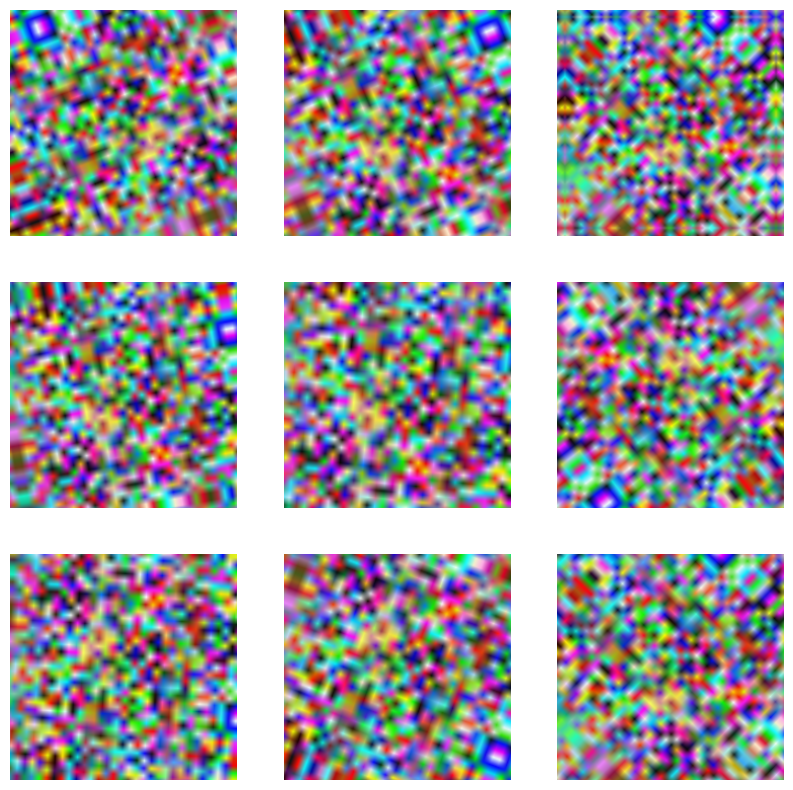

In [22]:
for image, _ in train_ds.take(1):
  plt.figure(figsize=(10, 10))
  first_image = image[0]
  for i in range(9):
    ax = plt.subplot(3, 3, i + 1)
    augmented_image = data_augmentation(tf.expand_dims(first_image, 0))
    plt.imshow(augmented_image[0] / 255)
    plt.axis('off')

In [23]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.cache().shuffle(1000).prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.prefetch(buffer_size=AUTOTUNE)

In [ ]:
QuantileTransformer, PCA, ADASYN, AUTOTUNE 